In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_excel(
    "MotoGP Data.ods",
    sheet_name="Arkusz1",
    engine="odf"
)

In [3]:
df.head()

,Year,Weekend,Track,Driver,Team,Constructor,FP1,FP1_sky,FP1_temp,FP1_conditions,...,FP2_sky,FP2_temp,FP2_conditions,FP2_humidity,FP2_ground,Q,Q_sky,Q_temp,Q_Humidity,Q_conditions
0,2026,THAILAND,Chang International Circuit,M. Bezzecchi,Aprilia Racing,Aprilia,01:29.346,Partly Cloudy,31.0,Dry,...,Partly Cloudy,28.0,Dry,0.73,31.0,01:28.652,Partly Cloudy,30,0.68,Dry
1,2026,THAILAND,Chang International Circuit,F. Di Giannantonio,Pertamina Enduro VR46 Racing Team,Ducati,01:29.456,Partly Cloudy,31.0,Dry,...,Partly Cloudy,28.0,Dry,0.73,31.0,01:28.918,Partly Cloudy,30,0.68,Dry
2,2026,THAILAND,Chang International Circuit,J. Martin,Aprilia Racing,Aprilia,01:29.551,Partly Cloudy,31.0,Dry,...,Partly Cloudy,28.0,Dry,0.73,31.0,01:29.001,Partly Cloudy,30,0.68,Dry
3,2026,THAILAND,Chang International Circuit,A. Ogura,Trackhouse MotoGP Team,Aprilia,01:29.655,Partly Cloudy,31.0,Dry,...,Partly Cloudy,28.0,Dry,0.73,31.0,01:29.211,Partly Cloudy,30,0.68,Dry
4,2026,THAILAND,Chang International Circuit,P. Acosta,Redbull KTM Factory Racing,KTM,01:29.678,Partly Cloudy,31.0,Dry,...,Partly Cloudy,28.0,Dry,0.73,31.0,01:29.061,Partly Cloudy,30,0.68,Dry


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1199 entries, 0 to 1198
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            1199 non-null   int64  
 1   Weekend         1199 non-null   object 
 2   Track           1199 non-null   object 
 3   Driver          1199 non-null   object 
 4   Team            1199 non-null   object 
 5   Constructor     1199 non-null   object 
 6   FP1             1177 non-null   object 
 7   FP1_sky         1177 non-null   object 
 8   FP1_temp        1155 non-null   float64
 9   FP1_conditions  1177 non-null   object 
 10  FP1_humidity    1155 non-null   float64
 11  FP1_ground      1155 non-null   float64
 12  PR              1198 non-null   object 
 13  PR_sky          1199 non-null   object 
 14  PR_temp         1199 non-null   int64  
 15  PR_conditions   1199 non-null   object 
 16  PR_humidity     1199 non-null   float64
 17  PR_ground       1199 non-null   i

In [5]:
df.describe()

,Year,FP1_temp,FP1_humidity,FP1_ground,PR_temp,PR_humidity,PR_ground,FP2_temp,FP2_humidity,FP2_ground,Q_temp,Q_Humidity
count,1199.000000,1155.000000,1155.000000,1155.000000,1199.000000,1199.000000,1199.000000,1155.000000,1155.000000,1155.00000,1199.000000,1199.000000
mean,2024.844871,22.010390,0.635610,30.535931,24.761468,0.538065,36.864053,21.531602,0.654528,28.69697,22.813178,0.609266
std,0.756246,5.130859,0.121248,9.238476,5.380496,0.158198,9.189838,5.250534,0.135691,9.64248,5.075240,0.137797
min,2024.000000,13.000000,0.390000,14.000000,14.000000,0.300000,20.000000,12.000000,0.360000,11.00000,13.000000,0.320000
25%,2024.000000,18.500000,0.560000,23.000000,20.000000,0.420000,29.000000,18.000000,0.560000,23.00000,19.000000,0.510000
50%,2025.000000,21.000000,0.630000,29.000000,24.000000,0.500000,37.000000,21.000000,0.660000,29.00000,22.000000,0.600000
75%,2025.000000,26.000000,0.710000,35.000000,29.000000,0.660000,44.000000,26.000000,0.755000,34.00000,27.000000,0.710000
max,2026.000000,33.000000,0.940000,55.000000,36.000000,0.920000,57.000000,33.000000,0.920000,49.00000,34.000000,0.870000


In [6]:
df.isna().sum()

Year               0
Weekend            0
Track              0
Driver             0
Team               0
Constructor        0
FP1               22
FP1_sky           22
FP1_temp          44
FP1_conditions    22
FP1_humidity      44
FP1_ground        44
PR                 1
PR_sky             0
PR_temp            0
PR_conditions      0
PR_humidity        0
PR_ground          0
FP2                0
FP2_sky            0
FP2_temp          44
FP2_conditions     0
FP2_humidity      44
FP2_ground        44
Q                  1
Q_sky              0
Q_temp             0
Q_Humidity         0
Q_conditions       0
dtype: int64

In [7]:
def lap_time_to_seconds(time_str):
    if pd.isna(time_str):
        return np.nan

    time_str = str(time_str).strip()

    if time_str in ["", "-", "DNS", "DNF", "No Time", "NOT"]:
        return np.nan

    try:
        minutes, seconds = time_str.split(":")
        return int(minutes) * 60 + float(seconds)
    except Exception:
        return np.nan

In [8]:
df.isna().sum()

Year               0
Weekend            0
Track              0
Driver             0
Team               0
Constructor        0
FP1               22
FP1_sky           22
FP1_temp          44
FP1_conditions    22
FP1_humidity      44
FP1_ground        44
PR                 1
PR_sky             0
PR_temp            0
PR_conditions      0
PR_humidity        0
PR_ground          0
FP2                0
FP2_sky            0
FP2_temp          44
FP2_conditions     0
FP2_humidity      44
FP2_ground        44
Q                  1
Q_sky              0
Q_temp             0
Q_Humidity         0
Q_conditions       0
dtype: int64

In [9]:
time_columns = ["FP1", "PR", "FP2", "Q"]

for col in time_columns:
    df[col] = df[col].apply(lap_time_to_seconds)

In [10]:
df = df.dropna(subset=['FP1', 'FP1_temp', 'FP1_humidity', 'FP1_ground', 'PR', 'FP2', 'FP2_temp', 'FP2_humidity', 'FP2_ground', 'Q'])

In [11]:
df.isna().sum()

Year              0
Weekend           0
Track             0
Driver            0
Team              0
Constructor       0
FP1               0
FP1_sky           0
FP1_temp          0
FP1_conditions    0
FP1_humidity      0
FP1_ground        0
PR                0
PR_sky            0
PR_temp           0
PR_conditions     0
PR_humidity       0
PR_ground         0
FP2               0
FP2_sky           0
FP2_temp          0
FP2_conditions    0
FP2_humidity      0
FP2_ground        0
Q                 0
Q_sky             0
Q_temp            0
Q_Humidity        0
Q_conditions      0
dtype: int64

In [12]:
df['Q_conditions'].describe()

count     1104
unique       2
top        Dry
freq      1037
Name: Q_conditions, dtype: object

In [13]:
df = df[(df["Q_conditions"] == "Dry")].copy()

In [14]:
def sort_by_quali_time(df, group_cols=['Year', 'Weekend', 'Track'], time_col='Q'):
    df_sorted = df.sort_values(by=group_cols + [time_col], ascending=True).reset_index(drop=True)
    df_sorted['quali_position'] = df_sorted.groupby(group_cols)[time_col].rank(method='min').astype(int)
    return df_sorted

df_sorted = sort_by_quali_time(df)

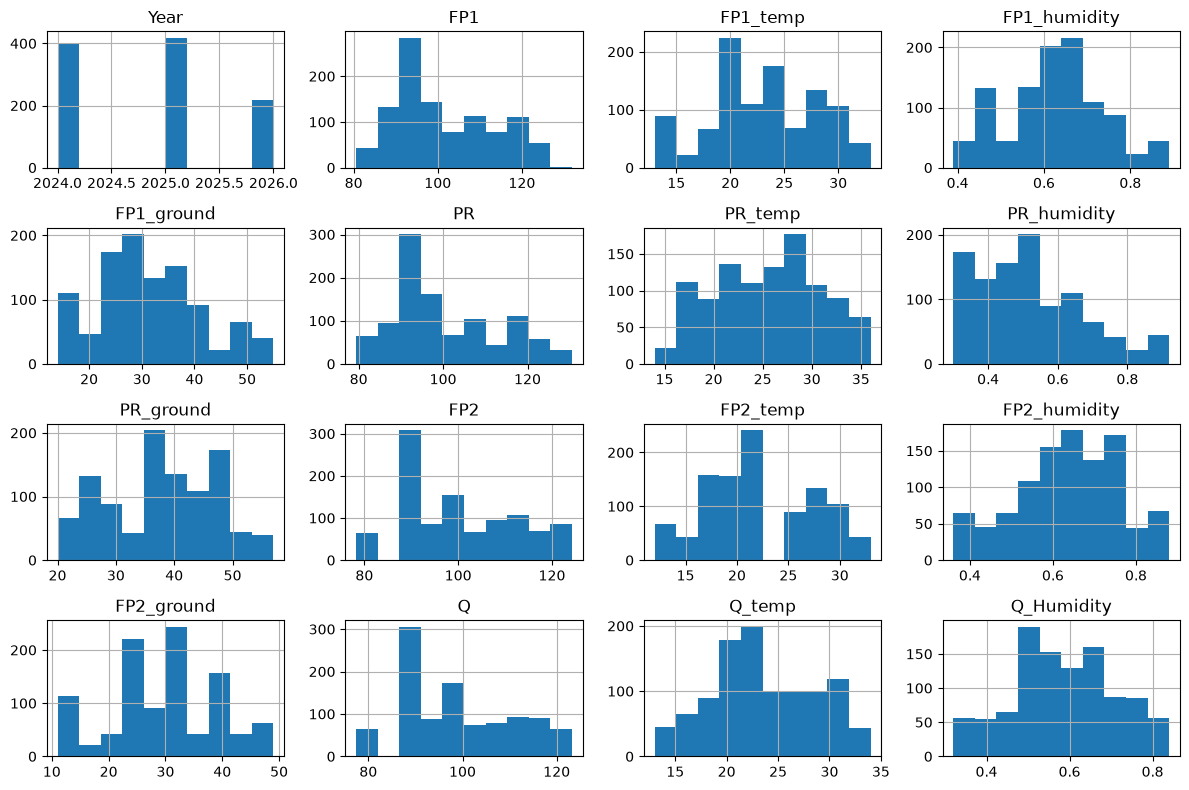

In [15]:
import matplotlib.pyplot as plt

df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1037 entries, 0 to 1198
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            1037 non-null   int64  
 1   Weekend         1037 non-null   object 
 2   Track           1037 non-null   object 
 3   Driver          1037 non-null   object 
 4   Team            1037 non-null   object 
 5   Constructor     1037 non-null   object 
 6   FP1             1037 non-null   float64
 7   FP1_sky         1037 non-null   object 
 8   FP1_temp        1037 non-null   float64
 9   FP1_conditions  1037 non-null   object 
 10  FP1_humidity    1037 non-null   float64
 11  FP1_ground      1037 non-null   float64
 12  PR              1037 non-null   float64
 13  PR_sky          1037 non-null   object 
 14  PR_temp         1037 non-null   int64  
 15  PR_conditions   1037 non-null   object 
 16  PR_humidity     1037 non-null   float64
 17  PR_ground       1037 non-null   int64 

In [17]:
features = [
    "Year",
    "Track",
    "Driver",
    "Team",
    "Constructor",
    "FP1",
    "FP1_sky",
    "FP1_temp",
    "FP1_conditions",
    "FP1_humidity",
    "FP1_ground",
    "PR",
    "PR_sky",
    "PR_temp",
    "PR_conditions",
    "PR_humidity",
    "PR_ground",
    "FP2",
    "FP2_sky",
    "FP2_temp",
    "FP2_conditions",
    "FP2_humidity",
    "FP2_ground",
    "Q_sky",
    "Q_temp",
    "Q_Humidity",
    "Q_conditions"
]

target = "Q"

In [18]:
data = df[features + [target]].dropna()

In [19]:
from sklearn.model_selection import train_test_split

X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical = ["Year", "Track", "Driver", "Team", "Constructor", "FP1_sky", "FP1_conditions", "PR_sky", "PR_conditions", "FP2_sky", "FP2_conditions", "Q_sky", "Q_conditions"]
numeric = [c for c in features if c not in categorical]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numeric)
    ]
)

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ))
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['Year','Track','Driver',...,'Q_temp','Q_Humidity','Q_conditions']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsi

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R²  :", r2_score(y_test, pred))

MAE : 0.26336040064103017
RMSE: 0.34057548511838814
R²  : 0.9991507187195242


In [23]:
comparison = X_test.copy()
comparison["Actual_Q"] = y_test.values
comparison["Predicted_Q"] = pred
comparison["Error"] = comparison["Predicted_Q"] - comparison["Actual_Q"]

comparison.head(10)

,Year,Track,Driver,Team,Constructor,FP1,FP1_sky,FP1_temp,FP1_conditions,FP1_humidity,...,FP2_conditions,FP2_humidity,FP2_ground,Q_sky,Q_temp,Q_Humidity,Q_conditions,Actual_Q,Predicted_Q,Error
735,2024,Lusail International Circuit,M. Vinales,Aprilia Racing,Aprilia,113.351,Clear,24.0,Dry,0.70,...,Dry,0.36,44.0,Clear,27,0.36,Dry,111.306,111.447577,0.141577
132,2026,Circuit de Barcelona-Catalunya,P. Acosta,Red Bull KTM Factory Racing,KTM,100.388,Cloudy,13.0,Dry,0.61,...,Dry,0.56,15.0,Clear,17,0.47,Dry,98.068,98.494560,0.426560
762,2024,Autódromo Internacional do Algarve,Miguel Oliveira,Trackhouse Racing,Aprilia,101.107,Cloudy,20.0,Dry,0.52,...,Dry,0.59,23.0,Cloudy,21,0.57,Dry,98.385,98.677000,0.292000
569,2025,Misano World Circuit Marco Simoncelli,M. Bezzecchi,Aprilia Racing,Aprilia,91.675,Clear,26.0,Dry,0.47,...,Dry,0.52,26.0,Clear,27,0.47,Dry,90.134,89.876703,-0.257297
653,2025,Phillip Island,L. Savadori,Aprilia Racing,Aprilia,89.791,Cloudy,14.0,Dry,0.68,...,Dry,0.75,14.0,Partly Cloudy,14,0.61,Dry,88.156,87.944600,-0.211400
631,2025,Pertamina Mandalika International Circuit,E. Bastianini,Red Bull KTM Tech3,KTM,92.113,Partly Cloudy,29.0,Dry,0.69,...,Dry,0.73,46.0,Partly Cloudy,30,0.70,Dry,90.242,90.191510,-0.050490
101,2026,Le Mans,M. Marquez,Ducati Lenovo Team,Ducati,91.388,Partly Cloudy,20.0,Dry,0.47,...,Dry,0.59,13.0,Clear,20,0.52,Dry,89.646,90.251383,0.605383
638,2025,Phillip Island,R. Fernandez,Trackhouse MotoGP Team,Aprilia,88.760,Cloudy,14.0,Dry,0.68,...,Dry,0.75,14.0,Partly Cloudy,14,0.62,Dry,86.851,86.976930,0.125930
856,2024,Circuit de Barcelona-Catalunya,J. Zarco,CASTROL Honda LCR,Honda,100.422,Cloudy,19.0,Dry,0.52,...,Dry,0.65,22.0,Partly Cloudy,20,0.57,Dry,98.978,99.516323,0.538323
1162,2024,Petronas Sepang International Circuit,A. Rins,Monster Energy Yamaha MotoGP Team,Yamaha,120.958,Partly Cloudy,30.0,Dry,0.77,...,Dry,0.77,33.0,Cloudy,29,0.69,Dry,117.726,117.484080,-0.241920


In [24]:
comparison.sort_values(
    "Error",
    key=abs,
    ascending=False
).head(20)

,Year,Track,Driver,Team,Constructor,FP1,FP1_sky,FP1_temp,FP1_conditions,FP1_humidity,...,FP2_conditions,FP2_humidity,FP2_ground,Q_sky,Q_temp,Q_Humidity,Q_conditions,Actual_Q,Predicted_Q,Error
377,2025,Silverstone Circuit,M. Vinales,Red Bull KTM Tech3,KTM,119.222,Partly Cloudy,15.0,Dry,0.46,...,Dry,0.82,23.0,Cloudy,17,0.77,Dry,119.159,118.193530,-0.965470
693,2025,Autódromo Internacional do Algarve,B. Binder,Red Bull KTM Factory Racing,KTM,100.185,Light Rain,19.0,Dry,0.68,...,Wet-Dry,0.67,22.0,Partly Cloudy,18,0.63,Dry,99.360,98.411873,-0.948127
1155,2024,Petronas Sepang International Circuit,J. Martin,Prima Pramac Racing,Ducati,120.442,Partly Cloudy,30.0,Dry,0.77,...,Dry,0.77,33.0,Cloudy,29,0.69,Dry,116.553,117.415863,0.862863
953,2024,Red Bull Ring - Spielberg,J. Martin,Prima Pramac Racing,Ducati,89.654,Partly Cloudy,25.0,Dry,0.61,...,Dry,0.72,28.0,Partly Cloudy,24,0.66,Dry,87.748,88.568473,0.820473
44,2026,Circuit of the Americas,J. Martin,Aprilia Racing,Aprilia,121.936,Partly Cloudy,23.0,Dry,0.66,...,Dry,0.51,23.0,Cloudy,16,0.48,Dry,120.696,119.879030,-0.816970
987,2024,MotorLand Aragón,Aleix Espargaro,Aprilia Racing,Aprilia,111.463,Clear,24.0,Dry,0.67,...,Dry,0.84,25.0,Cloudy,24,0.76,Dry,109.707,110.479037,0.772037
371,2025,Le Mans,A. Ogura,Trackhouse MotoGP Team,Aprilia,91.404,Partly Cloudy,14.0,Dry,0.63,...,Dry,0.58,13.0,Partly Cloudy,18,0.53,Dry,91.576,90.807123,-0.768877
994,2024,MotorLand Aragón,Takaaki Nakagami,IDEMITSU Honda LCR,Honda,109.655,Clear,24.0,Dry,0.67,...,Dry,0.84,25.0,Cloudy,23,0.80,Dry,109.081,109.819290,0.738290
746,2024,Lusail International Circuit,L. Marini,Repsol Honda Team,Honda,113.608,Clear,24.0,Dry,0.70,...,Dry,0.36,44.0,Clear,27,0.40,Dry,112.952,112.252947,-0.699053
895,2024,Silverstone Circuit,F. Di Giannantonio,Pertamina Enduro VR46 Racing Team,Ducati,119.830,Partly Cloudy,21.0,Dry,0.71,...,Dry,0.76,24.0,Cloudy,19,0.73,Dry,118.371,117.677707,-0.693293


In [25]:
df[["FP1", "PR", "FP2", "Q"]].corr()

,FP1,PR,FP2,Q
FP1,1.000000,0.972873,0.990566,0.991842
PR,0.972873,1.000000,0.966635,0.971442
FP2,0.990566,0.966635,1.000000,0.998287
Q,0.991842,0.971442,0.998287,1.000000


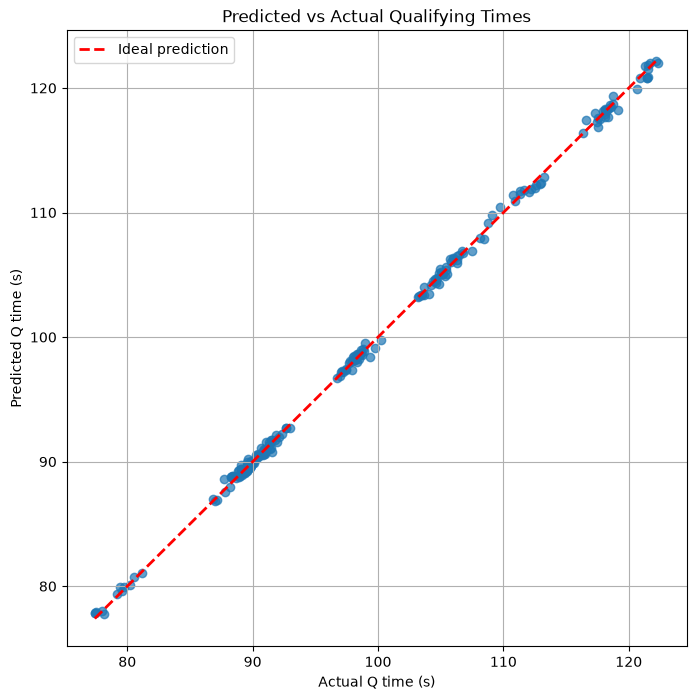

In [26]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 8))

plt.scatter(y_test, pred, alpha=0.7)

# Linia idealnych predykcji
min_val = min(y_test.min(), pred.min())
max_val = max(y_test.max(), pred.max())

plt.plot([min_val, max_val],
         [min_val, max_val],
         'r--',
         linewidth=2,
         label='Ideal prediction')

plt.xlabel("Actual Q time (s)")
plt.ylabel("Predicted Q time (s)")
plt.title("Predicted vs Actual Qualifying Times")
plt.legend()

plt.grid(True)
plt.show()

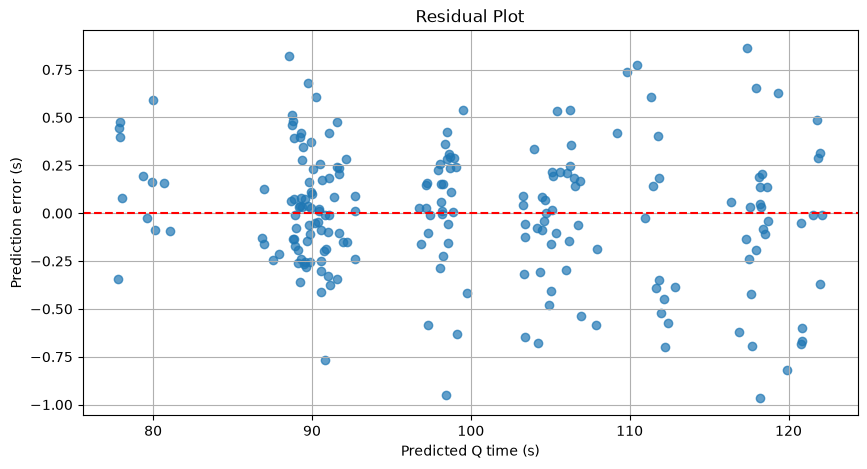

In [27]:
errors = pred - y_test

plt.figure(figsize=(10, 5))

plt.scatter(pred, errors, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Predicted Q time (s)")
plt.ylabel("Prediction error (s)")
plt.title("Residual Plot")

plt.grid(True)
plt.show()

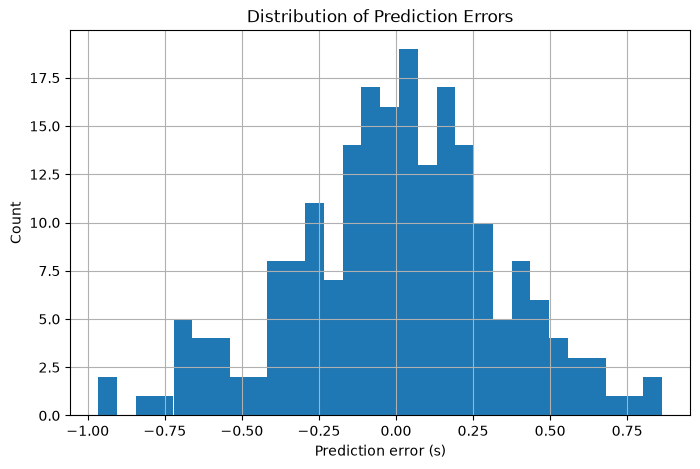

In [28]:
plt.figure(figsize=(8, 5))

plt.hist(errors, bins=30)

plt.xlabel("Prediction error (s)")
plt.ylabel("Count")
plt.title("Distribution of Prediction Errors")

plt.grid(True)
plt.show()

In [29]:
errors_ms = np.abs(pred - y_test) * 1000

print(f"Średni błąd: {errors_ms.mean():.0f} ms")
print(f"Mediana błędu: {np.median(errors_ms):.0f} ms")
print(f"90 percentyl: {np.percentile(errors_ms, 90):.0f} ms")
print(f"Maksymalny błąd: {errors_ms.max():.0f} ms")

Średni błąd: 263 ms
Mediana błędu: 204 ms
90 percentyl: 603 ms
Maksymalny błąd: 965 ms


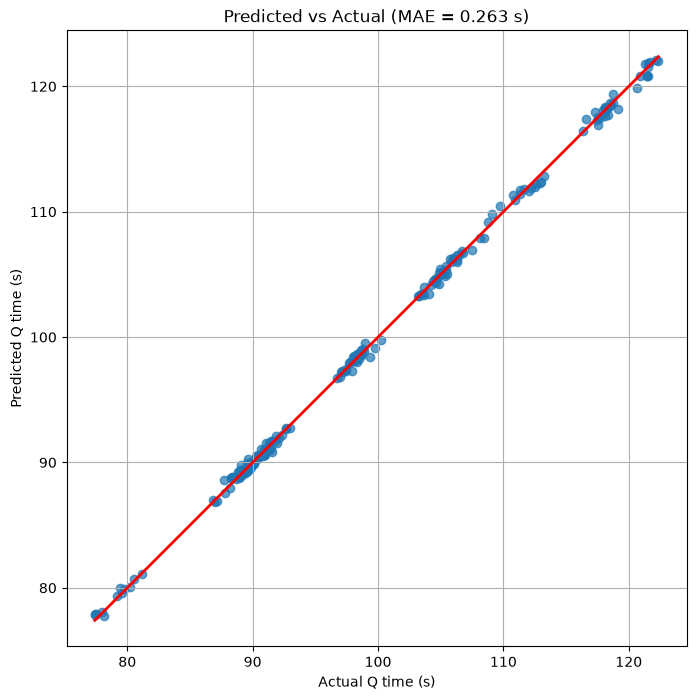

In [30]:
plt.figure(figsize=(8,8))

plt.scatter(y_test, pred, alpha=0.7)

min_val = min(y_test.min(), pred.min())
max_val = max(y_test.max(), pred.max())

plt.plot([min_val, max_val],
         [min_val, max_val],
         color='red',
         linewidth=2)

plt.xlabel("Actual Q time (s)")
plt.ylabel("Predicted Q time (s)")
plt.title(f"Predicted vs Actual (MAE = {mean_absolute_error(y_test, pred):.3f} s)")

plt.axis("equal")
plt.grid(True)

plt.show()

In [31]:
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1037 entries, 0 to 1198
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            1037 non-null   int64  
 1   Weekend         1037 non-null   object 
 2   Track           1037 non-null   object 
 3   Driver          1037 non-null   object 
 4   Team            1037 non-null   object 
 5   Constructor     1037 non-null   object 
 6   FP1             1037 non-null   float64
 7   FP1_sky         1037 non-null   object 
 8   FP1_temp        1037 non-null   float64
 9   FP1_conditions  1037 non-null   object 
 10  FP1_humidity    1037 non-null   float64
 11  FP1_ground      1037 non-null   float64
 12  PR              1037 non-null   float64
 13  PR_sky          1037 non-null   object 
 14  PR_temp         1037 non-null   int64  
 15  PR_conditions   1037 non-null   object 
 16  PR_humidity     1037 non-null   float64
 17  PR_ground       1037 non-null   int64 

In [33]:
features = [
    "Year",
    "Weekend",
    "Track",
    "Driver",
    "Team",
    "Constructor",
    "FP1",
    "FP1_sky",
    "FP1_temp",
    "FP1_conditions",
    "FP1_humidity",
    "FP1_ground",
    "PR",
    "PR_sky",
    "PR_temp",
    "PR_conditions",
    "PR_humidity",
    "PR_ground",
    "FP2",
    "FP2_sky",
    "FP2_temp",
    "FP2_conditions",
    "FP2_humidity",
    "FP2_ground",
    "Q_sky",
    "Q_temp",
    "Q_Humidity",
    "Q_conditions"
]

target = "Q"

data = df[features + [target]].dropna()

X = data[features]
y = data[target]

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [35]:
cat_features = [
    "Weekend",
    "Track",
    "Driver",
    "Team",
    "Constructor",
    "FP1_sky",
    "FP1_conditions",
    "PR_sky",
    "PR_conditions",
    "FP2_sky",
    "FP2_conditions",
    "Q_sky",
    "Q_conditions"
]

X_train["Year"] = X_train["Year"].astype(str)
X_test["Year"] = X_test["Year"].astype(str)

cat_features.append("Year")

In [36]:
model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.03,
    depth=6,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    verbose=100
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_features
)

0:	learn: 9.4737181	total: 208ms	remaining: 6m 55s
100:	learn: 1.1008699	total: 4.58s	remaining: 1m 26s
200:	learn: 0.3600281	total: 9.25s	remaining: 1m 22s
300:	learn: 0.2821520	total: 14s	remaining: 1m 18s
400:	learn: 0.2505801	total: 18.9s	remaining: 1m 15s
500:	learn: 0.2305190	total: 24.1s	remaining: 1m 12s
600:	learn: 0.2127514	total: 29s	remaining: 1m 7s
700:	learn: 0.1965537	total: 33.8s	remaining: 1m 2s
800:	learn: 0.1844743	total: 38.5s	remaining: 57.7s
900:	learn: 0.1747505	total: 43.5s	remaining: 53s
1000:	learn: 0.1662249	total: 48.1s	remaining: 48s
1100:	learn: 0.1585273	total: 52.9s	remaining: 43.2s
1200:	learn: 0.1523332	total: 57.5s	remaining: 38.3s
1300:	learn: 0.1468003	total: 1m 2s	remaining: 33.5s
1400:	learn: 0.1415787	total: 1m 6s	remaining: 28.6s
1500:	learn: 0.1371254	total: 1m 11s	remaining: 23.9s
1600:	learn: 0.1331857	total: 1m 17s	remaining: 19.3s
1700:	learn: 0.1292117	total: 1m 22s	remaining: 14.4s
1800:	learn: 0.1258834	total: 1m 26s	remaining: 9.56s
190

CatBoostRegressor(depth=6, eval_metric='MAE', iterations=2000, learning_rate=0.03, loss_function='MAE', random_seed=42, verbose=100)

In [37]:
pred = model.predict(X_test)

In [38]:
print(f"MAE : {mean_absolute_error(y_test, pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.3f}")
print(f"R²  : {r2_score(y_test, pred):.4f}")

MAE : 0.286
RMSE: 0.391
R²  : 0.9989


In [39]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

           Feature  Importance
6              FP1   28.907264
12              PR   23.152430
18             FP2   20.053866
24           Q_sky    3.936447
17       PR_ground    2.819406
19         FP2_sky    2.504702
23      FP2_ground    2.350788
16     PR_humidity    1.951596
9   FP1_conditions    1.774739
0             Year    1.629663
20        FP2_temp    1.517415
22    FP2_humidity    1.312534
26      Q_Humidity    1.124393
8         FP1_temp    1.101109
10    FP1_humidity    0.981679
2            Track    0.930501
13          PR_sky    0.852414
14         PR_temp    0.826794
25          Q_temp    0.690180
11      FP1_ground    0.538047
15   PR_conditions    0.433022
7          FP1_sky    0.244398
5      Constructor    0.168813
3           Driver    0.086378
4             Team    0.081580
1          Weekend    0.025659
21  FP2_conditions    0.004181
27    Q_conditions    0.000000


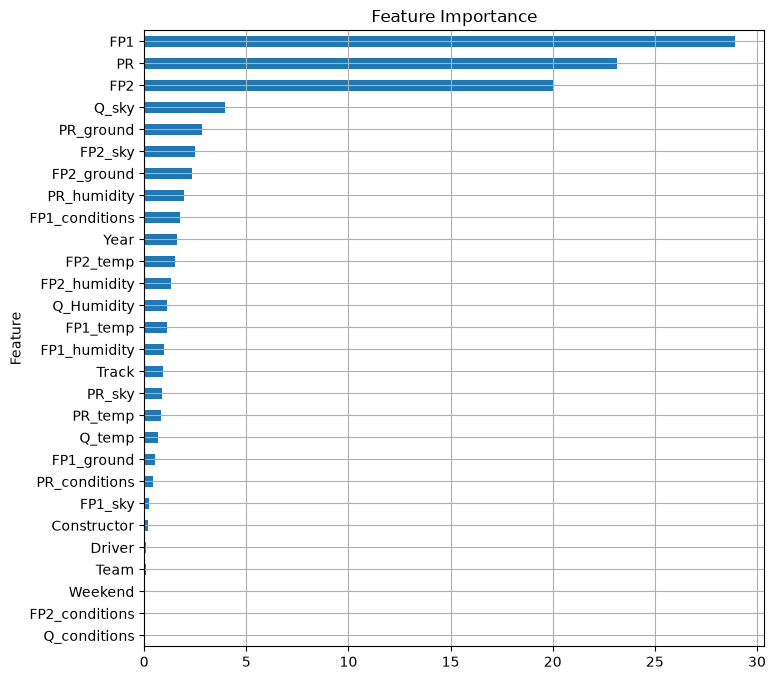

In [40]:
import matplotlib.pyplot as plt

importance.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(8,8),
    legend=False
)

plt.gca().invert_yaxis()
plt.title("Feature Importance")
plt.grid(True)
plt.show()

In [41]:
model = CatBoostRegressor(
    loss_function='MAE',
    iterations=5000,
    learning_rate=0.03,
    depth=10,
    l2_leaf_reg=3,
    early_stopping_rounds=50,
    eval_metric='MAE'
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_test, y_test),
    use_best_model=True,
    early_stopping_rounds=200
)

0:	learn: 9.5043672	test: 9.5003591	best: 9.5003591 (0)	total: 66.4ms	remaining: 5m 31s
1:	learn: 9.2255049	test: 9.2258362	best: 9.2258362 (1)	total: 156ms	remaining: 6m 29s
2:	learn: 8.9695389	test: 8.9579721	best: 8.9579721 (2)	total: 244ms	remaining: 6m 47s
3:	learn: 8.7200874	test: 8.7080565	best: 8.7080565 (3)	total: 284ms	remaining: 5m 55s
4:	learn: 8.5088389	test: 8.4963852	best: 8.4963852 (4)	total: 334ms	remaining: 5m 33s
5:	learn: 8.2848530	test: 8.2688666	best: 8.2688666 (5)	total: 383ms	remaining: 5m 18s
6:	learn: 8.0490300	test: 8.0265978	best: 8.0265978 (6)	total: 482ms	remaining: 5m 44s
7:	learn: 7.8313629	test: 7.8020454	best: 7.8020454 (7)	total: 510ms	remaining: 5m 18s
8:	learn: 7.6086828	test: 7.5792640	best: 7.5792640 (8)	total: 535ms	remaining: 4m 56s
9:	learn: 7.3892113	test: 7.3624065	best: 7.3624065 (9)	total: 635ms	remaining: 5m 16s
10:	learn: 7.1803647	test: 7.1448185	best: 7.1448185 (10)	total: 731ms	remaining: 5m 31s
11:	learn: 6.9680448	test: 6.9276700	bes

CatBoostRegressor(depth=10, early_stopping_rounds=50, eval_metric='MAE', iterations=5000, l2_leaf_reg=3, learning_rate=0.03, loss_function='MAE')

In [42]:
print(f"MAE : {mean_absolute_error(y_test, pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.3f}")
print(f"R²  : {r2_score(y_test, pred):.4f}")

MAE : 0.286
RMSE: 0.391
R²  : 0.9989


In [43]:
comparison = X_test.copy()
comparison["Actual_Q"] = y_test.values
comparison["Predicted_Q"] = pred
comparison["Error"] = comparison["Predicted_Q"] - comparison["Actual_Q"]

comparison.head(10)

,Year,Weekend,Track,Driver,Team,Constructor,FP1,FP1_sky,FP1_temp,FP1_conditions,...,FP2_conditions,FP2_humidity,FP2_ground,Q_sky,Q_temp,Q_Humidity,Q_conditions,Actual_Q,Predicted_Q,Error
735,2024,QATAR,Lusail International Circuit,M. Vinales,Aprilia Racing,Aprilia,113.351,Clear,24.0,Dry,...,Dry,0.36,44.0,Clear,27,0.36,Dry,111.306,111.242681,-0.063319
132,2026,CATALONIA,Circuit de Barcelona-Catalunya,P. Acosta,Red Bull KTM Factory Racing,KTM,100.388,Cloudy,13.0,Dry,...,Dry,0.56,15.0,Clear,17,0.47,Dry,98.068,98.584052,0.516052
762,2024,PORTUGAL,Autódromo Internacional do Algarve,Miguel Oliveira,Trackhouse Racing,Aprilia,101.107,Cloudy,20.0,Dry,...,Dry,0.59,23.0,Cloudy,21,0.57,Dry,98.385,98.887782,0.502782
569,2025,SAN MARINO,Misano World Circuit Marco Simoncelli,M. Bezzecchi,Aprilia Racing,Aprilia,91.675,Clear,26.0,Dry,...,Dry,0.52,26.0,Clear,27,0.47,Dry,90.134,90.189090,0.055090
653,2025,AUSTRALIA,Phillip Island,L. Savadori,Aprilia Racing,Aprilia,89.791,Cloudy,14.0,Dry,...,Dry,0.75,14.0,Partly Cloudy,14,0.61,Dry,88.156,87.855374,-0.300626
631,2025,INDONESIA,Pertamina Mandalika International Circuit,E. Bastianini,Red Bull KTM Tech3,KTM,92.113,Partly Cloudy,29.0,Dry,...,Dry,0.73,46.0,Partly Cloudy,30,0.70,Dry,90.242,90.320043,0.078043
101,2026,FRANCE,Le Mans,M. Marquez,Ducati Lenovo Team,Ducati,91.388,Partly Cloudy,20.0,Dry,...,Dry,0.59,13.0,Clear,20,0.52,Dry,89.646,90.174345,0.528345
638,2025,AUSTRALIA,Phillip Island,R. Fernandez,Trackhouse MotoGP Team,Aprilia,88.760,Cloudy,14.0,Dry,...,Dry,0.75,14.0,Partly Cloudy,14,0.62,Dry,86.851,86.642753,-0.208247
856,2024,CATALONIA,Circuit de Barcelona-Catalunya,J. Zarco,CASTROL Honda LCR,Honda,100.422,Cloudy,19.0,Dry,...,Dry,0.65,22.0,Partly Cloudy,20,0.57,Dry,98.978,98.588792,-0.389208
1162,2024,MALAYSIA,Petronas Sepang International Circuit,A. Rins,Monster Energy Yamaha MotoGP Team,Yamaha,120.958,Partly Cloudy,30.0,Dry,...,Dry,0.77,33.0,Cloudy,29,0.69,Dry,117.726,117.414572,-0.311428


In [44]:
comparison.sort_values(
    "Error",
    key=abs,
    ascending=False
).head(20)

,Year,Weekend,Track,Driver,Team,Constructor,FP1,FP1_sky,FP1_temp,FP1_conditions,...,FP2_conditions,FP2_humidity,FP2_ground,Q_sky,Q_temp,Q_Humidity,Q_conditions,Actual_Q,Predicted_Q,Error
994,2024,ARAGON,MotorLand Aragón,Takaaki Nakagami,IDEMITSU Honda LCR,Honda,109.655,Clear,24.0,Dry,...,Dry,0.84,25.0,Cloudy,23,0.80,Dry,109.081,110.633513,1.552513
371,2025,FRANCE,Le Mans,A. Ogura,Trackhouse MotoGP Team,Aprilia,91.404,Partly Cloudy,14.0,Dry,...,Dry,0.58,13.0,Partly Cloudy,18,0.53,Dry,91.576,90.166097,-1.409903
1054,2026,UNITED KINGDOM,Silverstone Circuit,B. Binder,Red Bull KTM Factory Racing,KTM,119.797,Partly Cloudy,19.0,Dry,...,Dry,0.43,31.0,Partly Cloudy,23,0.32,Dry,118.081,116.840368,-1.240632
795,2024,USA,Circuit Of The Americas,M. Vinales,Aprilia Racing,Aprilia,123.294,Clear,21.0,Dry,...,Dry,0.76,28.0,Partly Cloudy,23,0.62,Dry,120.864,122.088257,1.224257
1108,2024,JAPAN,Mobility Resort Motegi,L. Savadori,Trackhouse Racing,Aprilia,108.642,Cloudy,24.0,Dry,...,Dry,0.85,23.0,Cloudy,21,0.83,Dry,105.422,106.569148,1.147148
328,2025,QATAR,Lusail International Circuit,Somkiat Chantra,IDEMITSU Honda LCR,Honda,114.364,Clear,30.0,Dry,...,Dry,0.41,49.0,Clear,32,0.38,Dry,113.244,112.206511,-1.037489
1194,2024,SOLIDARITY,Circuit de Barcelona-Catalunya,J. Miller,Red Bull KTM Factory Racing,KTM,101.178,Partly Cloudy,13.0,Dry,...,Dry,0.88,11.0,Clear,13,0.83,Dry,99.749,98.724311,-1.024689
1028,2024,Emilia-Romagna,Misano World Circuit Marco Simoncelli,M. Marquez,Gresini Racing MotoGP,Ducati,92.082,Partly Cloudy,21.0,Wet,...,Dry,0.72,23.0,Clear,22,0.67,Dry,90.880,89.906702,-0.973298
107,2026,FRANCE,Le Mans,J. Folger,Red Bull KTM Tech3,KTM,94.098,Partly Cloudy,20.0,Dry,...,Dry,0.59,13.0,Clear,20,0.52,Dry,91.826,92.698765,0.872765
919,2024,NETHERLANDS,TT Circuit Assen,R. Fernandez,Trackhouse Racing,Aprilia,92.501,Partly Cloudy,20.0,Dry,...,Dry,0.57,32.0,Partly Cloudy,21,0.50,Dry,91.928,91.061882,-0.866118


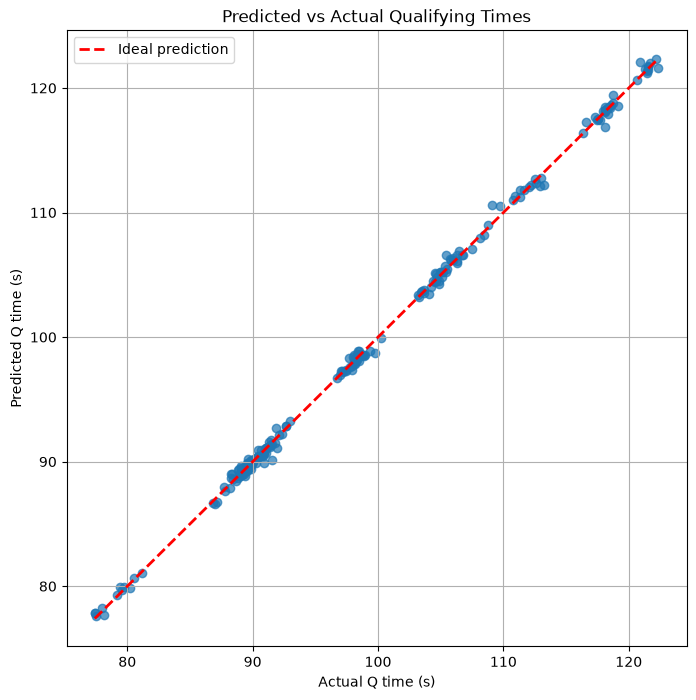

In [45]:
plt.figure(figsize=(8, 8))

plt.scatter(y_test, pred, alpha=0.7)

# Linia idealnych predykcji
min_val = min(y_test.min(), pred.min())
max_val = max(y_test.max(), pred.max())

plt.plot([min_val, max_val],
         [min_val, max_val],
         'r--',
         linewidth=2,
         label='Ideal prediction')

plt.xlabel("Actual Q time (s)")
plt.ylabel("Predicted Q time (s)")
plt.title("Predicted vs Actual Qualifying Times")
plt.legend()

plt.grid(True)
plt.show()

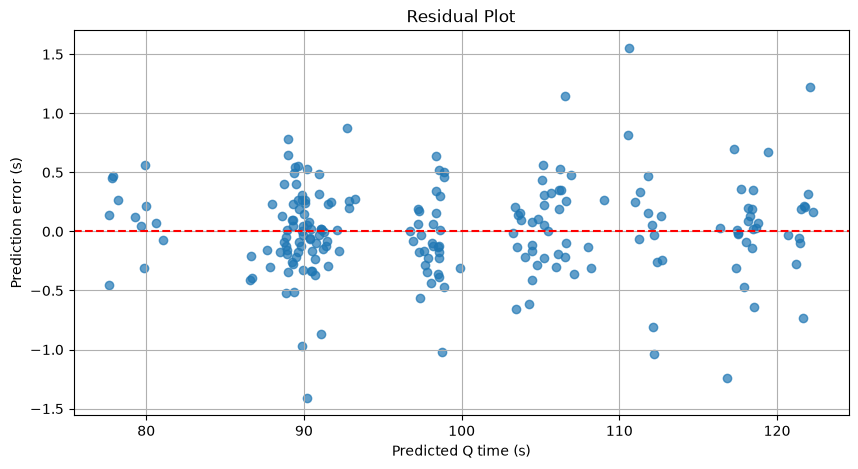

In [46]:
errors = pred - y_test

plt.figure(figsize=(10, 5))

plt.scatter(pred, errors, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Predicted Q time (s)")
plt.ylabel("Prediction error (s)")
plt.title("Residual Plot")

plt.grid(True)
plt.show()

In [47]:
X = df[['FP1', 'PR', 'FP2']]
y = df['Q']

naive_pred = X.min(axis=1)
print(mean_absolute_error(y, naive_pred))

0.4697020250723237


In [48]:
fp2_mae = mean_absolute_error(y, X['FP2'])
print(fp2_mae)

1.1878476374156217


<Axes: >

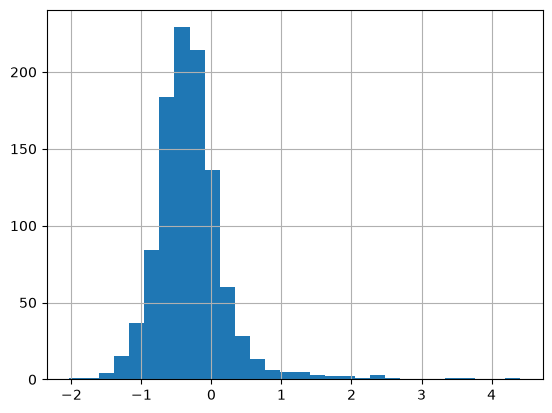

In [49]:
diff = y - X.min(axis=1)
diff.describe()
diff.hist(bins=30)

In [50]:
diff = y - X.min(axis=1)
outliers = df[diff > 3].copy()
outliers['diff'] = diff[diff > 3]

print(outliers[['Year', 'Weekend', 'Track', 'Driver', 
                 'FP1_conditions', 'PR_conditions', 'FP2_conditions',
                 'FP1', 'PR', 'FP2', 'Q', 'diff']].sort_values('diff', ascending=False))

     Year    Weekend                            Track           Driver  \
988  2024     ARAGON                MotorLand Aragón        M. Vinales   
987  2024     ARAGON                MotorLand Aragón   Aleix Espargaro   
148  2026  CATALONIA  Circuit de Barcelona-Catalunya   T. Razgatlioglu   

    FP1_conditions PR_conditions FP2_conditions      FP1       PR      FP2  \
988            Dry           Dry            Dry  109.449  106.117  111.481   
987            Dry           Dry            Dry  111.463  106.073  114.269   
148            Dry           Dry            Dry  101.940   99.531  100.371   

           Q   diff  
988  110.526  4.409  
987  109.707  3.634  
148  102.945  3.414  


In [51]:
jerez_2026 = df[(df['Track'].str.contains('Jerez')) & (df['Year'] == 2026)]
print(jerez_2026[['Driver', 'FP1_conditions', 'PR_conditions', 'FP2_conditions', 'Q_conditions']] 
      if 'Q_conditions' in df.columns else 
      jerez_2026[['Driver', 'FP1_conditions', 'PR_conditions', 'FP2_conditions']])

Empty DataFrame
Columns: [Driver, FP1_conditions, PR_conditions, FP2_conditions, Q_conditions]
Index: []


In [52]:
from sklearn.model_selection import GroupKFold

# Grupa łącząca rok i weekend, żeby uniknąć mieszania różnych lat tego samego toru
groups = df['Year'].astype(str) + '_' + df['Weekend']

X = df[['FP1', 'PR', 'FP2']]  # docelowo dodasz więcej cech
y = df['Q']

gkf = GroupKFold(n_splits=7)

rf_scores = []
cat_scores = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups=groups)):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # --- Random Forest ---
    rf = RandomForestRegressor(random_state=42, n_estimators=300)
    rf.fit(X_train, y_train)
    rf_pred = rf.predict(X_test)
    rf_mae = mean_absolute_error(y_test, rf_pred)
    rf_scores.append(rf_mae)

    # --- CatBoost ---
    cat = CatBoostRegressor(
        loss_function='MAE',
        eval_metric='MAE',
        iterations=1000,
        learning_rate=0.03,
        depth=4,
        l2_leaf_reg=10,
        verbose=False,
        random_seed=42
    )
    cat.fit(X_train, y_train)
    cat_pred = cat.predict(X_test)
    cat_mae = mean_absolute_error(y_test, cat_pred)
    cat_scores.append(cat_mae)

    print(f"Fold {fold+1}: RF MAE = {rf_mae:.3f} | CatBoost MAE = {cat_mae:.3f}")

print(f"\nRF   - średnie MAE: {np.mean(rf_scores):.3f} (+/- {np.std(rf_scores):.3f})")
print(f"CatBoost - średnie MAE: {np.mean(cat_scores):.3f} (+/- {np.std(cat_scores):.3f})")

Fold 1: RF MAE = 0.350 | CatBoost MAE = 0.321
Fold 2: RF MAE = 0.322 | CatBoost MAE = 0.407
Fold 3: RF MAE = 0.326 | CatBoost MAE = 0.315
Fold 4: RF MAE = 0.334 | CatBoost MAE = 0.330
Fold 5: RF MAE = 0.335 | CatBoost MAE = 0.500
Fold 6: RF MAE = 1.152 | CatBoost MAE = 1.103
Fold 7: RF MAE = 0.379 | CatBoost MAE = 0.482

RF   - średnie MAE: 0.457 (+/- 0.284)
CatBoost - średnie MAE: 0.494 (+/- 0.258)
